In [1]:
import jax
import flax
import optax
from jax import lax, random, numpy as jnp
from jax import random, grad, vmap, hessian, jacfwd, jit
from jax import config
from flax import linen as nn
from scipy.integrate import odeint
from jax.scipy.linalg import solve

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# choose GPU
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '1'
jax.config.update("jax_enable_x64", True)

# get_ipython().system('pip install evojax')
from evojax.util import get_params_format_fn

In [2]:
file_path = "/home/wongj/weizhao/biology/0721/Theophylline PBPK Model ODEs.xlsx"
# file_path = "Paracetamol PBPK Model ODEs_revised for IV dosing.xlsx"
data_sheets = pd.read_excel(file_path, sheet_name=None)

In [3]:
data = data_sheets['Compartments']
for name, value in zip(data['Name'], data['Value']):
    globals()[name] = value

data = data_sheets['Parameters']
for name, value in zip(data['Name'], data['Value']):
    globals()[name] = value

# data = data_sheets['Species']
# for name, value in zip(data['Name'], data['Value (at t = 0 h)']):
#     globals()[name] = value

In [4]:
n_s = 200  # number of samples
n_e = 22  # number of equations
t_max = 10

t_in = jnp.linspace(0, t_max, n_s).reshape(-1, 1)

2026-01-21 20:16:26.512095: W external/xla/xla/service/gpu/nvptx_compiler.cc:893] The NVIDIA driver's CUDA version is 12.4 which is older than the PTX compiler version 12.6.68. Because the driver is older than the PTX compiler version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


In [5]:
# ground truth obtained by the ODE solver
def biology_ODEs(y, t):
    y1, y2, y3, y4, y5, y6, y7, y8, y9, y10, y11, y12, y13, y14, y15, y16, y17, y18, y19, y20, y21, y22 = y
    source_term = jnp.where(t <= 2/3, 450/SP_VenousBlood, 0)
    dy1dt = -1/SP_ArterialBlood*y1*(SP_Q_Brain+SP_Q_Heart+SP_Q_Stomach+SP_Q_Spleen+SP_Q_Pancreas+SP_Q_HepaticArtery+SP_Q_Adipose+SP_Q_Skin+SP_Q_Muscle+SP_Q_Bone+SP_Q_RestOfBody+SP_Q_Kidney+SP_Q_Duodenum+SP_Q_Jejunum+SP_Q_Ileum+SP_Q_LargeIntestine) + SP_Q_Lung*DP_BP/(SP_ArterialBlood*Kp_LungAdjusted)*y4
    dy2dt = -SP_Q_Lung*y2/SP_VenousBlood + SP_Q_Brain*y3*DP_BP/(Kp_BrainAdjusted*SP_VenousBlood) + SP_Q_Heart*y5*DP_BP/(Kp_HeartAdjusted*SP_VenousBlood) + SP_Q_Liver*y20*DP_BP/(Kp_LiverAdjusted*SP_VenousBlood) + SP_Q_Adipose*y8*DP_BP/(Kp_AdiposeAdjusted*SP_VenousBlood) + SP_Q_Skin*y9*DP_BP/(Kp_SkinAdjusted*SP_VenousBlood) + SP_Q_Muscle*y10*DP_BP/(Kp_MuscleAdjusted*SP_VenousBlood) + SP_Q_Bone*y11*DP_BP/(Kp_BoneAdjusted*SP_VenousBlood) + SP_Q_RestOfBody*y12*DP_BP/(Kp_RestOfBodyAdjusted*SP_VenousBlood) + SP_Q_Kidney*y13*DP_BP/(Kp_KidneyAdjusted*SP_VenousBlood) + source_term
    dy3dt = -SP_Q_Brain*DP_BP*y3/(Kp_BrainAdjusted*SP_Brain) + SP_Q_Brain*y1/SP_Brain
    dy4dt = -SP_Q_Lung*y4*DP_BP/(SP_Lung*Kp_LungAdjusted) + SP_Q_Lung*y2/SP_Lung
    dy5dt = -SP_Q_Heart*y5*DP_BP/(SP_Heart*Kp_HeartAdjusted) + SP_Q_Heart*y1/SP_Heart
    dy6dt = -SP_Q_Spleen*y6*DP_BP/(SP_Spleen*Kp_SpleenAdjusted) + SP_Q_Spleen*y1/SP_Spleen
    dy7dt = -SP_Q_Pancreas*y7*DP_BP/(SP_Pancreas*Kp_PancreasAdjusted) + SP_Q_Pancreas*y1/SP_Pancreas
    dy8dt = -SP_Q_Adipose*y8*DP_BP/(SP_Adipose*Kp_AdiposeAdjusted) + SP_Q_Adipose*y1/SP_Adipose
    dy9dt = -SP_Q_Skin*y9*DP_BP/(SP_Skin*Kp_SkinAdjusted) + SP_Q_Skin*y1/SP_Skin
    dy10dt = -SP_Q_Muscle*y10*DP_BP/(SP_Muscle*Kp_MuscleAdjusted) + SP_Q_Muscle*y1/SP_Muscle
    dy11dt = -SP_Q_Bone*y11*DP_BP/(SP_Bone*Kp_BoneAdjusted) + SP_Q_Bone*y1/SP_Bone
    dy12dt = -SP_Q_RestOfBody*y12*DP_BP/(SP_RestOfBody*Kp_RestOfBodyAdjusted) + SP_Q_RestOfBody*y1/SP_RestOfBody
    dy13dt = -SP_Q_Kidney*y13*DP_BP/(SP_Kidney*Kp_KidneyAdjusted) - DP_CLR*y13/SP_Kidney + SP_Q_Kidney*y1/SP_Kidney
    dy14dt = -(SP_Q_PortalVein*y14)/PortalVein + (SP_Q_Stomach*y15*DP_BP)/(PortalVein*Kp_GutAdjusted) + (SP_Q_Spleen*y6*DP_BP)/(PortalVein*Kp_SpleenAdjusted) + (SP_Q_Pancreas*y7*DP_BP)/(PortalVein*Kp_PancreasAdjusted) + (SP_Q_Duodenum*y16*DP_BP)/(PortalVein*Kp_GutAdjusted) + (SP_Q_Jejunum*y17*DP_BP)/(PortalVein*Kp_GutAdjusted) + (SP_Q_Ileum*y18*DP_BP)/(PortalVein*Kp_GutAdjusted) + (SP_Q_LargeIntestine*y19*DP_BP)/(PortalVein*Kp_GutAdjusted)
    dy15dt = -SP_Q_Stomach*y15*DP_BP/(SP_Stomach*Kp_GutAdjusted) + SP_Q_Stomach*y1/SP_Stomach
    dy16dt = -SP_Q_Duodenum*y16*DP_BP/(SP_DuodenumWall*Kp_GutAdjusted) + SP_Q_Duodenum*y1/SP_DuodenumWall
    dy17dt = -SP_Q_Jejunum*y17*DP_BP/(SP_JejunumWall*Kp_GutAdjusted) + SP_Q_Jejunum*y1/SP_JejunumWall
    dy18dt = -SP_Q_Ileum*y18*DP_BP/(SP_IleumWall*Kp_GutAdjusted) + SP_Q_Ileum*y1/SP_IleumWall
    dy19dt = -SP_Q_LargeIntestine*y19*DP_BP/(SP_LargeIntestineWall*Kp_GutAdjusted) + SP_Q_LargeIntestine*y1/SP_LargeIntestineWall
    dy20dt = -SP_Q_Liver*y20*DP_BP/(SP_Liver*Kp_LiverAdjusted) - y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_1MX_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub)) - y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_3MX_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub)) - y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_DMU_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub)) - y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_2E1_DMU_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub)) + SP_Q_PortalVein*y14/SP_Liver + SP_Q_HepaticArtery*y1/SP_Liver
    dy21dt = y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_1MX_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub)) + y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_3MX_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub)) + y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_DMU_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub)) + y20*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_2E1_DMU_Liver*DP_fu_incubation + y20/DP_DrugMW*DP_fub))
    dy22dt = DP_CLR*y13/SP_Urine

    dydt = jnp.array([dy1dt, dy2dt, dy3dt, dy4dt, dy5dt, dy6dt, dy7dt, dy8dt, dy9dt, dy10dt, dy11dt, dy12dt, dy13dt, dy14dt, dy15dt, dy16dt, dy17dt, dy18dt, dy19dt, dy20dt, dy21dt, dy22dt])
    return dydt

# def biology_ODEs(y, t):
#     y1, y2, y3, y4, y5, y6, y7, y8, y9, y10, y11, y12, y13, y14, y15, y16, y17, y18, y19, y20, y21, y22 = y
#     source_term = jnp.where(t <= 2/3, 450/SP_VenousBlood, 0)
#     dy1dt = 1/SP_ArterialBlood*(((SP_Q_Lung*y4*DP_BP)/(Kp_LungAdjusted)) - (SP_Q_Brain*y1) - (SP_Q_Heart*y1) - (SP_Q_Stomach*y1) - (SP_Q_Spleen*y1) - (SP_Q_Pancreas*y1) - (SP_Q_HepaticArtery*y1) - (SP_Q_Adipose*y1) - (SP_Q_Skin*y1) - (SP_Q_Muscle*y1) - (SP_Q_Bone*y1) - (SP_Q_RestOfBody*y1) - (SP_Q_Kidney*y1) - (SP_Q_Duodenum*y1) - (SP_Q_Jejunum*y1) - (SP_Q_Ileum*y1) - (SP_Q_LargeIntestine*y1))
#     dy2dt = 1/SP_VenousBlood*(-(SP_Q_Lung*y2) + ((SP_Q_Brain*y3*DP_BP)/(Kp_BrainAdjusted)) + ((SP_Q_Heart*y5*DP_BP)/(Kp_HeartAdjusted)) + ((SP_Q_Liver*y20*DP_BP)/(Kp_LiverAdjusted)) + ((SP_Q_Adipose*y8*DP_BP)/(Kp_AdiposeAdjusted)) + ((SP_Q_Skin*y9*DP_BP)/(Kp_SkinAdjusted)) + ((SP_Q_Muscle*y10*DP_BP)/(Kp_MuscleAdjusted)) + ((SP_Q_Bone*y11*DP_BP)/(Kp_BoneAdjusted)) + ((SP_Q_RestOfBody*y12*DP_BP)/(Kp_RestOfBodyAdjusted)) + ((SP_Q_Kidney*y13*DP_BP)/(Kp_KidneyAdjusted))) + source_term
#     dy3dt = 1/SP_Brain*((SP_Q_Brain*y1) - ((SP_Q_Brain*y3*DP_BP)/(Kp_BrainAdjusted)))
#     dy4dt = 1/SP_Lung*((SP_Q_Lung*y2) - ((SP_Q_Lung*y4*DP_BP)/(Kp_LungAdjusted)))
#     dy5dt = 1/SP_Heart*((SP_Q_Heart*y1) - ((SP_Q_Heart*y5*DP_BP)/(Kp_HeartAdjusted)))
#     dy6dt = 1/SP_Spleen*((SP_Q_Spleen*y1) - ((SP_Q_Spleen*y6*DP_BP)/(Kp_SpleenAdjusted)))
#     dy7dt = 1/SP_Pancreas*((SP_Q_Pancreas*y1) - ((SP_Q_Pancreas*y7*DP_BP)/(Kp_PancreasAdjusted)))
#     dy8dt = 1/SP_Adipose*((SP_Q_Adipose*y1) - ((SP_Q_Adipose*y8*DP_BP)/(Kp_AdiposeAdjusted)))
#     dy9dt = 1/SP_Skin*((SP_Q_Skin*y1) - ((SP_Q_Skin*y9*DP_BP)/(Kp_SkinAdjusted)))
#     dy10dt = 1/SP_Muscle*((SP_Q_Muscle*y1) - ((SP_Q_Muscle*y10*DP_BP)/(Kp_MuscleAdjusted)))
#     dy11dt = 1/SP_Bone*((SP_Q_Bone*y1) - ((SP_Q_Bone*y11*DP_BP)/(Kp_BoneAdjusted)))
#     dy12dt = 1/SP_RestOfBody*((SP_Q_RestOfBody*y1) - ((SP_Q_RestOfBody*y12*DP_BP)/(Kp_RestOfBodyAdjusted)))
#     dy13dt = 1/SP_Kidney*((SP_Q_Kidney*y1) - ((SP_Q_Kidney*y13*DP_BP)/(Kp_KidneyAdjusted)) - (DP_CLR*y13))
#     dy14dt = 1/PortalVein*(((SP_Q_Stomach*y15*DP_BP)/(Kp_GutAdjusted)) + ((SP_Q_Spleen*y6*DP_BP)/(Kp_SpleenAdjusted)) + ((SP_Q_Pancreas*y7*DP_BP)/(Kp_PancreasAdjusted)) - (SP_Q_PortalVein*y14) + ((SP_Q_Duodenum*y16*DP_BP)/(Kp_GutAdjusted)) + ((SP_Q_Jejunum*y17*DP_BP)/(Kp_GutAdjusted)) + ((SP_Q_Ileum*y18*DP_BP)/(Kp_GutAdjusted)) + ((SP_Q_LargeIntestine*y19*DP_BP)/(Kp_GutAdjusted)))
#     dy15dt = 1/SP_Stomach*((SP_Q_Stomach*y1) - ((SP_Q_Stomach*y15*DP_BP)/(Kp_GutAdjusted)))
#     dy16dt = 1/SP_DuodenumWall*((SP_Q_Duodenum*y1) - ((SP_Q_Duodenum*y16*DP_BP)/(Kp_GutAdjusted)))
#     dy17dt = 1/SP_JejunumWall*((SP_Q_Jejunum*y1) - ((SP_Q_Jejunum*y17*DP_BP)/(Kp_GutAdjusted)))
#     dy18dt = 1/SP_IleumWall*((SP_Q_Ileum*y1) - ((SP_Q_Ileum*y18*DP_BP)/(Kp_GutAdjusted)))
#     dy19dt = 1/SP_LargeIntestineWall*((SP_Q_LargeIntestine*y1) - ((SP_Q_LargeIntestine*y19*DP_BP)/(Kp_GutAdjusted)))
#     dy20dt = 1/SP_Liver*((SP_Q_PortalVein*y14) + (SP_Q_HepaticArtery*y1) - ((SP_Q_Liver*y20*DP_BP)/(Kp_LiverAdjusted)) - ((DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver)/(DP_Km_1A2_1MX_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted) - ((DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver)/(DP_Km_1A2_3MX_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted) - ((DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver)/(DP_Km_1A2_DMU_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted) - ((DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver)/(DP_Km_2E1_DMU_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted))
#     dy21dt = 1/SP_Liver*(((DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver)/(DP_Km_1A2_1MX_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted) + ((DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver)/(DP_Km_1A2_3MX_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted) + ((DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver)/(DP_Km_1A2_DMU_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted) + ((DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver)/(DP_Km_2E1_DMU_Liver*DP_fu_incubation+((y20/DP_DrugMW)*DP_fub))*SP_MPPGL*SP_LiverWeight*(y20*DP_fub)*DP_BP/Kp_LiverAdjusted))
#     dy22dt = 1/SP_Urine*((DP_CLR*y13))

#     dydt = jnp.array([dy1dt, dy2dt, dy3dt, dy4dt, dy5dt, dy6dt, dy7dt, dy8dt, dy9dt, dy10dt, dy11dt, dy12dt, dy13dt, dy14dt, dy15dt, dy16dt, dy17dt, dy18dt, dy19dt, dy20dt, dy21dt, dy22dt])
#     return dydt


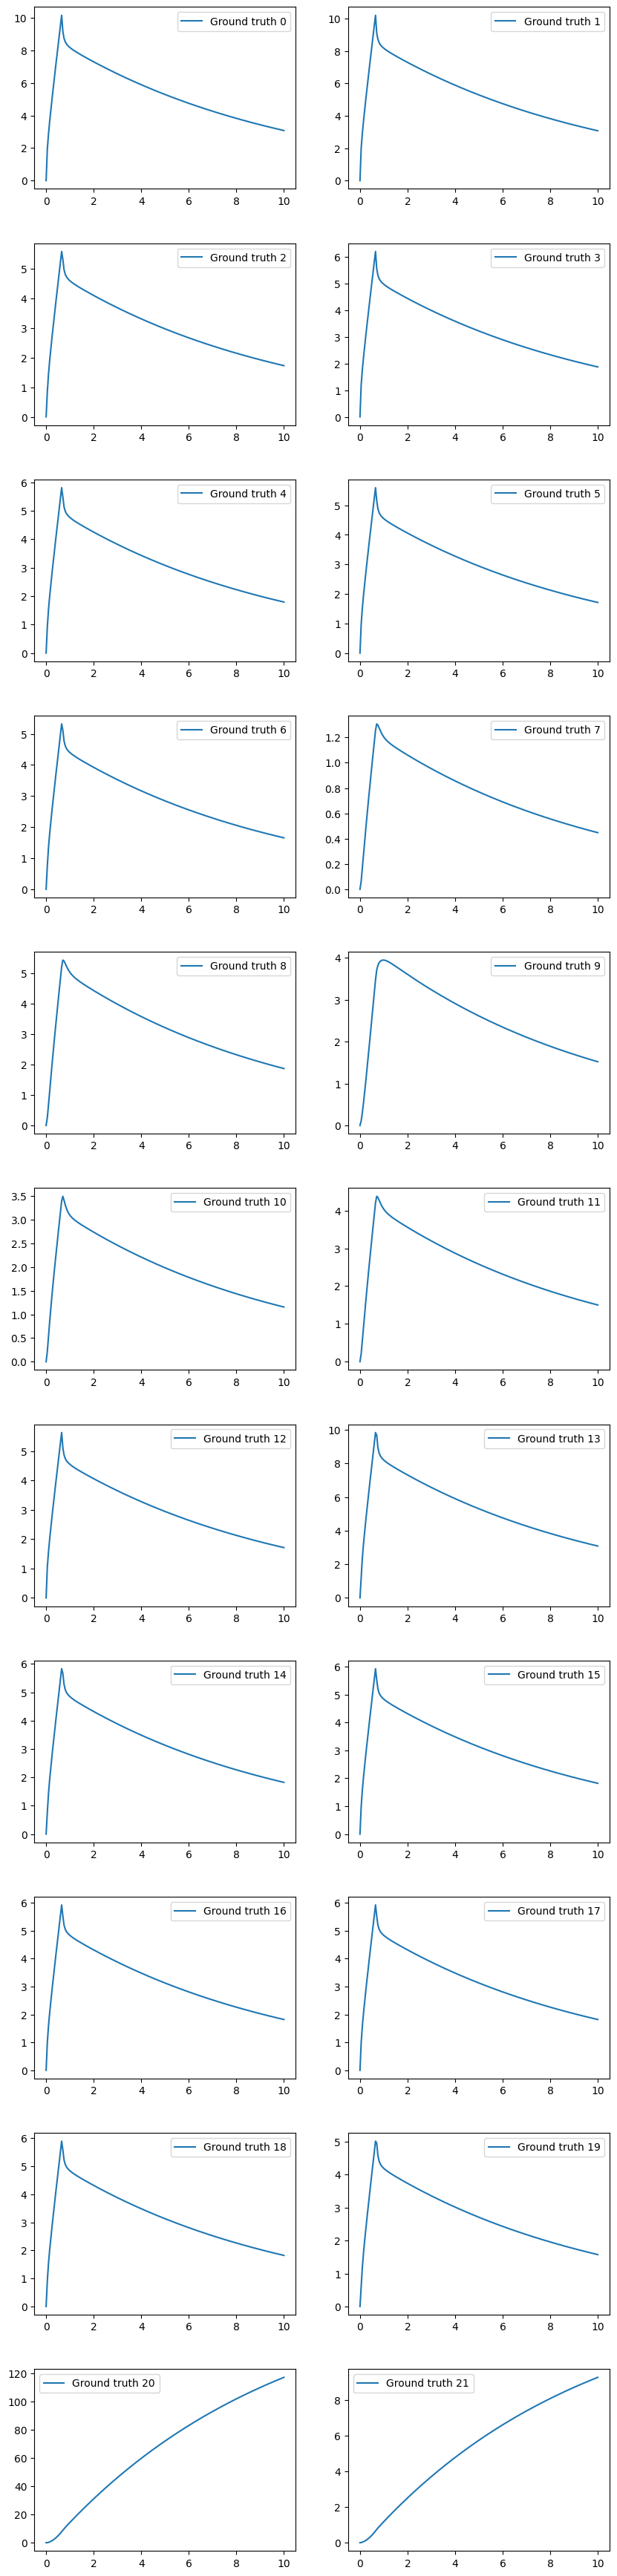

In [6]:
# key = random.PRNGKey(0)
# y0 = random.uniform(key, shape=(33,))

# y0 = 1e-2*jnp.ones((33,))
y0 = jnp.zeros((n_e,))
# y0 = y0.at[14].set(10)
t_in0 = jnp.linspace(0, t_max, n_s)
gt_solver = odeint(biology_ODEs, y0, t_in0)

num_rows = 11
num_cols = 2
num_images = num_rows * num_cols

fig = plt.figure(figsize=(10, 35))

subfigs = fig.subfigures(num_rows, 1)

for row in range(num_rows):
    axs = subfigs[row].subplots(1, num_cols)
    for col in range(num_cols):
        idx = row * num_cols + col
        axs[col].plot(t_in, gt_solver[:, idx], label=f'Ground truth {idx}')
        axs[col].legend()
plt.show()




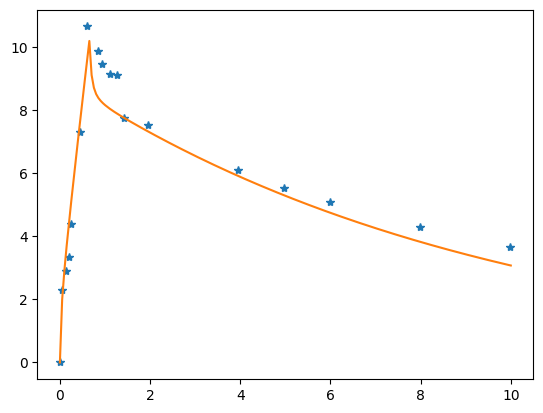

In [7]:
file_path = "/home/wongj/weizhao/biology/0721/Clinical Data Summary_Dose Normalized.xlsx"
sheet_name = "Chrzanowski 1977 S1 Dose 1"
df = pd.read_excel(file_path, sheet_name=sheet_name)
clinical_data_t = df["Time, h"].to_numpy()
clinical_data_concentration = df["Plasma conc., mg/L"].to_numpy()

plt.figure()
plt.plot(clinical_data_t, clinical_data_concentration*DP_BP, '*', label='clinical data')
plt.plot(t_in, gt_solver[:, 1], label='clinical data')

In [8]:
clinical_data_t1 = np.array([0.000, 0.057, 0.143, 0.212, 0.247, 0.450, 0.591, 0.856, 0.944, 1.106, 1.276, 1.428, 1.953, 3.947, 4.967, 5.987, 7.989, 9.977])
clinical_data_concentration1 = np.array([0.000, 2.835, 3.559, 4.091, 5.378, 8.967, 13.073, 12.127, 11.621, 11.210, 11.189, 9.518, 9.256, 7.487, 6.797, 6.244, 5.279, 4.509])

clinical_data_t2 = np.array([0.000, 0.019, 0.049, 0.123, 0.327, 0.553, 0.976, 1.146, 1.318, 1.801, 2.728, 3.767, 5.720, 7.770, 9.800])
clinical_data_concentration2 = np.array([0.000, 2.304, 4.424, 6.095, 9.501, 12.353, 10.544, 9.969, 8.428, 9.353, 7.695, 7.591, 5.372, 4.318, 3.874])

clinical_data_t3 = np.array([0.000, 0.078, 0.147, 0.172, 0.346, 0.419, 0.645, 0.830, 0.880, 1.116, 1.284, 1.985, 3.874, 4.893, 5.760, 7.803, 9.933])
clinical_data_concentration3 = np.array([0.000, 1.444, 4.256, 6.575, 7.941, 10.826, 13.850, 12.004, 11.131, 9.802, 8.230, 9.686, 7.785, 6.549, 5.587, 4.728, 4.672])

clinical_data_t4 = np.array([0.000, 0.080, 0.109, 0.202, 0.326, 0.460, 0.610, 0.807, 0.847, 0.947, 1.144, 1.301, 1.483, 2.020, 3.953, 4.944, 5.951, 7.926, 9.900])
clinical_data_concentration4 = np.array([0.000, 2.268, 5.233, 6.565, 7.035, 9.829, 11.094, 9.314, 7.582, 8.860, 7.048, 6.981, 6.539, 6.552, 5.459, 5.212, 4.410, 3.724, 3.150])

clinical_data_t5 = np.array([0.000, 0.169, 0.212, 0.375, 0.471, 0.647, 0.861, 1.045, 1.138, 1.313, 1.441, 2.019, 3.072, 3.961, 6.008, 7.988])
clinical_data_concentration5 = np.array([0.000, 4.510, 7.148, 7.284, 10.994, 14.038, 11.505, 11.061, 9.717, 8.552, 7.373, 7.038, 5.611, 5.459, 4.803, 4.225])

clinical_data_t6 = np.array([0.000, 0.110, 0.199, 0.225, 0.429, 0.597, 0.867, 1.077, 1.131, 1.365, 1.906, 2.885, 3.912, 4.946, 5.952, 9.948])
clinical_data_concentration6 = np.array([0.000, 6.152, 5.808, 8.646, 11.471, 13.482, 11.213, 10.306, 9.937, 9.996, 9.495, 6.446, 7.213, 6.396, 6.340, 4.918])

clinical_data_t7 = np.array([0.000, 0.046, 0.124, 0.246, 0.308, 0.444, 0.613, 0.770, 0.954, 1.117, 1.274, 1.953, 3.703, 4.957, 7.941])
clinical_data_concentration7 = np.array([0.000, 2.296, 4.367, 6.585, 6.934, 7.904, 8.677, 7.968, 8.048, 8.113, 7.495, 6.911, 5.808, 5.574, 4.330])

clinical_data_t8 = np.array([0.000, 0.127, 0.161, 0.283, 0.412, 0.679, 0.920, 1.015, 1.253, 1.554, 2.004, 3.025, 4.000, 4.976, 8.024])
clinical_data_concentration8 = np.array([0.000, 5.248, 7.276, 9.173, 10.087, 10.030, 8.666, 9.694, 8.783, 8.618, 8.735, 8.237, 7.159, 6.093, 4.967])

In [9]:
# DNN / PINN
class PINN(nn.Module):
    """PINNs"""
    def setup(self):
      #single hidden layer
        self.layers = [nn.Dense(n_nodes, kernel_init = jax.nn.initializers.he_uniform()),
                       jnp.sin,
                       nn.Dense(n_nodes, kernel_init = jax.nn.initializers.he_uniform()),
                    #    jnp.sin,
                    #    nn.Dense(n_nodes, kernel_init = jax.nn.initializers.he_uniform()),
                       # jnp.sin,
                    #    nn.Dense(n_nodes, kernel_init = jax.nn.initializers.he_uniform()),
                       jnp.sin]
        #self.last_layer = nn.Dense(1, kernel_init = jax.nn.initializers.he_uniform(), use_bias=False)


    @nn.compact
    def __call__(self, inputs):
        # split the two variables, probably just by slicing
        t = inputs
        def get_u(t):
            f = t / 10
            #f = t
            fs = []
            for i, lyr in enumerate(self.layers):
                f = lyr(f)
                """For sin activation"""
                if (i == 0):
                # if (i == 0) | (i == 2) | (i == 4):
                    f = 2*jnp.pi*f #first hidden layer mult by 2pi
            #     if (i%2 != 0):
            #         fs.append(f)
            # f = jnp.hstack(fs) #stop at the hidden layer before output
            #u = self.last_layer(f)
            return f

        f = get_u(t)

        # obtain f_t
        def get_f_dir(get_u, t):
            f_t = jacfwd(get_u)(t)  # much faster (10x) than u_xx, f_xx = hessian(get_u)(x, y)
            return f_t

        f_dir_vmap = vmap(get_f_dir, in_axes=(None, 0))
        f_t = f_dir_vmap(get_u, t)
        f_t = f_t[:,:,0]

        outputs = jnp.hstack([f, f_t])
        return outputs

In [10]:
# choose seed
seed = 5 # does not work for 0, work best for 10
key, rng = random.split(random.PRNGKey(seed))

# dummy input
a = random.normal(key, [1, 1]) #only for t

# initialization call
#n_nodes = 512
n_nodes = 256
#n_nodes = 128
#n_nodes = 64
model = PINN()
params = model.init(key, a)
num_params, format_params_fn = get_params_format_fn(params)

# flatten initial params
params = jax.flatten_util.ravel_pytree(params)[0]

key, rng = random.split(rng) # update random generator
ini_a = random.normal(key, [1, 1]) #one for lmbda, other for lambda
params = jnp.append(params, ini_a)
print(params.shape)

params = jnp.load('/home/wongj/weizhao/biology/0721/best_22equations_new_drug1.npy')
print(params.shape)

(66305,)
(66305,)


In [11]:
def regularization_factor(params):
  reg = 10**(nn.sigmoid(params)*7 - 10)
  return reg

def km_factor(params):
  km = 10**(nn.sigmoid(params)*1 + 2)
  return km

def Vmax_factor(params):
  km = 10**(nn.sigmoid(params)*1 - 4)
  return km

In [12]:
# P-I solution
# SGD + P-I training

# loss function
def eval_loss(params_inv):
    # pred = model.apply(format_params_fn(params[:-(n_e + 1)]), t_in)
    pred = model.apply(format_params_fn(params[:-1]), t_in)
    f, f_t = jnp.split(pred, 2, axis=1)

    pred_data1 = model.apply(format_params_fn(params[:-1]), clinical_data_t1.reshape(-1, 1))
    f_data1, f_t_data1 = jnp.split(pred_data1, 2, axis=1)

    pred_data2 = model.apply(format_params_fn(params[:-1]), clinical_data_t2.reshape(-1, 1))
    f_data2, f_t_data2 = jnp.split(pred_data2, 2, axis=1)

    pred_data3 = model.apply(format_params_fn(params[:-1]), clinical_data_t3.reshape(-1, 1))
    f_data3, f_t_data3 = jnp.split(pred_data3, 2, axis=1)

    pred_data4 = model.apply(format_params_fn(params[:-1]), clinical_data_t4.reshape(-1, 1))
    f_data4, f_t_data4 = jnp.split(pred_data4, 2, axis=1)

    pred_data5 = model.apply(format_params_fn(params[:-1]), clinical_data_t5.reshape(-1, 1))
    f_data5, f_t_data5 = jnp.split(pred_data5, 2, axis=1)

    pred_data6 = model.apply(format_params_fn(params[:-1]), clinical_data_t6.reshape(-1, 1))
    f_data6, f_t_data6 = jnp.split(pred_data6, 2, axis=1)

    pred_data7 = model.apply(format_params_fn(params[:-1]), clinical_data_t7.reshape(-1, 1))
    f_data7, f_t_data7 = jnp.split(pred_data7, 2, axis=1)

    pred_data8 = model.apply(format_params_fn(params[:-1]), clinical_data_t8.reshape(-1, 1))
    f_data8, f_t_data8 = jnp.split(pred_data8, 2, axis=1)

    DP_Km_1A2_DMU_Liver = km_factor(params_inv[0])
    DP_Vmax_1A2_DMU_Liver = Vmax_factor(params_inv[1])

    ic_A1 = jnp.zeros((1, n_e*n_nodes))
    ic_A1 = ic_A1.at[:, 0*n_nodes:1*n_nodes].set(f[0:1])

    ic_A2 = jnp.zeros((1, n_e*n_nodes))
    ic_A2 = ic_A2.at[:, 1*n_nodes:2*n_nodes].set(f[0:1])

    ic_A3 = jnp.zeros((1, n_e*n_nodes))
    ic_A3 = ic_A3.at[:, 2*n_nodes:3*n_nodes].set(f[0:1])

    ic_A4 = jnp.zeros((1, n_e*n_nodes))
    ic_A4 = ic_A4.at[:, 3*n_nodes:4*n_nodes].set(f[0:1])

    ic_A5 = jnp.zeros((1, n_e*n_nodes))
    ic_A5 = ic_A5.at[:, 4*n_nodes:5*n_nodes].set(f[0:1])

    ic_A6 = jnp.zeros((1, n_e*n_nodes))
    ic_A6 = ic_A6.at[:, 5*n_nodes:6*n_nodes].set(f[0:1])

    ic_A7 = jnp.zeros((1, n_e*n_nodes))
    ic_A7 = ic_A7.at[:, 6*n_nodes:7*n_nodes].set(f[0:1])

    ic_A8 = jnp.zeros((1, n_e*n_nodes))
    ic_A8 = ic_A8.at[:, 7*n_nodes:8*n_nodes].set(f[0:1])

    ic_A9 = jnp.zeros((1, n_e*n_nodes))
    ic_A9 = ic_A9.at[:, 8*n_nodes:9*n_nodes].set(f[0:1])

    ic_A10 = jnp.zeros((1, n_e*n_nodes))
    ic_A10 = ic_A10.at[:, 9*n_nodes:10*n_nodes].set(f[0:1])

    ic_A11 = jnp.zeros((1, n_e*n_nodes))
    ic_A11 = ic_A11.at[:, 10*n_nodes:11*n_nodes].set(f[0:1])

    ic_A12 = jnp.zeros((1, n_e*n_nodes))
    ic_A12 = ic_A12.at[:, 11*n_nodes:12*n_nodes].set(f[0:1])

    ic_A13 = jnp.zeros((1, n_e*n_nodes))
    ic_A13 = ic_A13.at[:, 12*n_nodes:13*n_nodes].set(f[0:1])

    ic_A14 = jnp.zeros((1, n_e*n_nodes))
    ic_A14 = ic_A14.at[:, 13*n_nodes:14*n_nodes].set(f[0:1])

    ic_A15 = jnp.zeros((1, n_e*n_nodes))
    ic_A15 = ic_A15.at[:, 14*n_nodes:15*n_nodes].set(f[0:1])

    ic_A16 = jnp.zeros((1, n_e*n_nodes))
    ic_A16 = ic_A16.at[:, 15*n_nodes:16*n_nodes].set(f[0:1])

    ic_A17 = jnp.zeros((1, n_e*n_nodes))
    ic_A17 = ic_A17.at[:, 16*n_nodes:17*n_nodes].set(f[0:1])

    ic_A18 = jnp.zeros((1, n_e*n_nodes))
    ic_A18 = ic_A18.at[:, 17*n_nodes:18*n_nodes].set(f[0:1])

    ic_A19 = jnp.zeros((1, n_e*n_nodes))
    ic_A19 = ic_A19.at[:, 18*n_nodes:19*n_nodes].set(f[0:1])

    ic_A20 = jnp.zeros((1, n_e*n_nodes))
    ic_A20 = ic_A20.at[:, 19*n_nodes:20*n_nodes].set(f[0:1])

    ic_A21 = jnp.zeros((1, n_e*n_nodes))
    ic_A21 = ic_A21.at[:, 20*n_nodes:21*n_nodes].set(f[0:1])

    ic_A22 = jnp.zeros((1, n_e*n_nodes))
    ic_A22 = ic_A22.at[:, 21*n_nodes:22*n_nodes].set(f[0:1])

    ic_A = jnp.vstack([ic_A1, ic_A2, ic_A3, ic_A4, ic_A5, ic_A6, ic_A7, ic_A8, ic_A9, ic_A10, ic_A11, ic_A12, ic_A13, ic_A14, ic_A15, ic_A16, ic_A17, ic_A18, ic_A19, ic_A20, ic_A21, ic_A22])
    ic_b = jnp.zeros((ic_A.shape[0], 1))

    # data_A = jnp.zeros((clinical_data_t.shape[0], n_e*n_nodes))
    # data_A = data_A.at[:, 1*n_nodes:2*n_nodes].set(f_data)
    # data_b = jnp.array(clinical_data_concentration).reshape(-1, 1)*DP_BP

    data_b1 = jnp.array(clinical_data_concentration1).reshape(-1, 1)*DP_BP
    data_b2 = jnp.array(clinical_data_concentration2).reshape(-1, 1)*DP_BP
    data_b3 = jnp.array(clinical_data_concentration3).reshape(-1, 1)*DP_BP
    data_b4 = jnp.array(clinical_data_concentration4).reshape(-1, 1)*DP_BP
    data_b5 = jnp.array(clinical_data_concentration5).reshape(-1, 1)*DP_BP
    data_b6 = jnp.array(clinical_data_concentration6).reshape(-1, 1)*DP_BP
    data_b7 = jnp.array(clinical_data_concentration7).reshape(-1, 1)*DP_BP
    data_b8 = jnp.array(clinical_data_concentration8).reshape(-1, 1)*DP_BP

    initial_guess_value = 0
    for i in range(6):
        # PDEs
        # PDE 1
        pde_A1 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A1 = pde_A1.at[:, 0:n_nodes].set(-1/SP_ArterialBlood*f*(SP_Q_Brain + SP_Q_Heart + SP_Q_Stomach + SP_Q_Spleen + SP_Q_Pancreas + SP_Q_HepaticArtery + SP_Q_Adipose + SP_Q_Skin + SP_Q_Muscle + SP_Q_Bone + SP_Q_RestOfBody + SP_Q_Kidney + SP_Q_Duodenum + SP_Q_Jejunum + SP_Q_Ileum + SP_Q_LargeIntestine) - f_t)
        pde_A1 = pde_A1.at[:, 3*n_nodes:4*n_nodes].set(SP_Q_Lung*DP_BP/(SP_ArterialBlood*Kp_LungAdjusted)*f)

        # PDE 2
        pde_A2 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A2 = pde_A2.at[:, 1*n_nodes:2*n_nodes].set(-f_t - SP_Q_Lung*f/SP_VenousBlood)
        pde_A2 = pde_A2.at[:, 2*n_nodes:3*n_nodes].set(SP_Q_Brain*f*DP_BP/(Kp_BrainAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 4*n_nodes:5*n_nodes].set(SP_Q_Heart*f*DP_BP/(Kp_HeartAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 19*n_nodes:20*n_nodes].set(SP_Q_Liver*f*DP_BP/(Kp_LiverAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 7*n_nodes:8*n_nodes].set(SP_Q_Adipose*f*DP_BP/(Kp_AdiposeAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 8*n_nodes:9*n_nodes].set(SP_Q_Skin*f*DP_BP/(Kp_SkinAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 9*n_nodes:10*n_nodes].set(SP_Q_Muscle*f*DP_BP/(Kp_MuscleAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 10*n_nodes:11*n_nodes].set(SP_Q_Bone*f*DP_BP/(Kp_BoneAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 11*n_nodes:12*n_nodes].set(SP_Q_RestOfBody*f*DP_BP/(Kp_RestOfBodyAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 12*n_nodes:13*n_nodes].set(SP_Q_Kidney*f*DP_BP/(Kp_KidneyAdjusted*SP_VenousBlood))

        # PDE 3
        pde_A3 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A3 = pde_A3.at[:, 2*n_nodes:3*n_nodes].set(-f_t - SP_Q_Brain*DP_BP*f/(Kp_BrainAdjusted*SP_Brain))
        pde_A3 = pde_A3.at[:, 0:1*n_nodes].set(SP_Q_Brain*f/SP_Brain)

        # PDE 4
        pde_A4 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A4 = pde_A4.at[:, 3*n_nodes:4*n_nodes].set(-f_t - SP_Q_Lung*f*DP_BP/(SP_Lung*Kp_LungAdjusted))
        pde_A4 = pde_A4.at[:, 1*n_nodes:2*n_nodes].set(SP_Q_Lung*f/SP_Lung)

        # PDE 5
        pde_A5 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A5 = pde_A5.at[:, 4*n_nodes:5*n_nodes].set(-f_t - SP_Q_Heart*f*DP_BP/(SP_Heart*Kp_HeartAdjusted))
        pde_A5 = pde_A5.at[:, 0:1*n_nodes].set(SP_Q_Heart*f/SP_Heart)

        # PDE 6
        pde_A6 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A6 = pde_A6.at[:, 5*n_nodes:6*n_nodes].set(-f_t - SP_Q_Spleen*f*DP_BP/(SP_Spleen*Kp_SpleenAdjusted))
        pde_A6 = pde_A6.at[:, 0:1*n_nodes].set(SP_Q_Spleen*f/SP_Spleen)

        # PDE 7
        pde_A7 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A7 = pde_A7.at[:, 6*n_nodes:7*n_nodes].set(-f_t - SP_Q_Pancreas*f*DP_BP/(SP_Pancreas*Kp_PancreasAdjusted))
        pde_A7 = pde_A7.at[:, 0:1*n_nodes].set(SP_Q_Pancreas*f/SP_Pancreas)

        # PDE 8
        pde_A8 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A8 = pde_A8.at[:, 7*n_nodes:8*n_nodes].set(-f_t - SP_Q_Adipose*f*DP_BP/(SP_Adipose*Kp_AdiposeAdjusted))
        pde_A8 = pde_A8.at[:, 0:1*n_nodes].set(SP_Q_Adipose*f/SP_Adipose)

        # PDE 9
        pde_A9 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A9 = pde_A9.at[:, 8*n_nodes:9*n_nodes].set(-f_t - SP_Q_Skin*f*DP_BP/(SP_Skin*Kp_SkinAdjusted))
        pde_A9 = pde_A9.at[:, 0:1*n_nodes].set(SP_Q_Skin*f/SP_Skin)

        # PDE 10
        pde_A10 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A10 = pde_A10.at[:, 9*n_nodes:10*n_nodes].set(-f_t - SP_Q_Muscle*f*DP_BP/(SP_Muscle*Kp_MuscleAdjusted))
        pde_A10 = pde_A10.at[:, 0:1*n_nodes].set(SP_Q_Muscle*f/SP_Muscle)

        # PDE 11
        pde_A11 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A11 = pde_A11.at[:, 10*n_nodes:11*n_nodes].set(-f_t - SP_Q_Bone*f*DP_BP/(SP_Bone*Kp_BoneAdjusted))
        pde_A11 = pde_A11.at[:, 0:1*n_nodes].set(SP_Q_Bone*f/SP_Bone)

        # PDE 12
        pde_A12 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A12 = pde_A12.at[:, 11*n_nodes:12*n_nodes].set(-f_t - SP_Q_RestOfBody*f*DP_BP/(SP_RestOfBody*Kp_RestOfBodyAdjusted))
        pde_A12 = pde_A12.at[:, 0:1*n_nodes].set(SP_Q_RestOfBody*f/SP_RestOfBody)

        # PDE 13
        pde_A13 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A13 = pde_A13.at[:, 12*n_nodes:13*n_nodes].set(-f_t - SP_Q_Kidney*f*DP_BP/(SP_Kidney*Kp_KidneyAdjusted) - DP_CLR*f/SP_Kidney)
        pde_A13 = pde_A13.at[:, 0:1*n_nodes].set(SP_Q_Kidney*f/SP_Kidney)

        # PDE 14
        pde_A14 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A14 = pde_A14.at[:, 13*n_nodes:14*n_nodes].set(-f_t - (SP_Q_PortalVein*f)/PortalVein)
        pde_A14 = pde_A14.at[:, 14*n_nodes:15*n_nodes].set((SP_Q_Stomach*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 5*n_nodes:6*n_nodes].set((SP_Q_Spleen*f*DP_BP)/(PortalVein*Kp_SpleenAdjusted))
        pde_A14 = pde_A14.at[:, 6*n_nodes:7*n_nodes].set((SP_Q_Pancreas*f*DP_BP)/(PortalVein*Kp_PancreasAdjusted))
        pde_A14 = pde_A14.at[:, 15*n_nodes:16*n_nodes].set((SP_Q_Duodenum*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 16*n_nodes:17*n_nodes].set((SP_Q_Jejunum*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 17*n_nodes:18*n_nodes].set((SP_Q_Ileum*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 18*n_nodes:19*n_nodes].set((SP_Q_LargeIntestine*f*DP_BP)/(PortalVein*Kp_GutAdjusted))

        # PDE 15
        pde_A15 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A15 = pde_A15.at[:, 14*n_nodes:15*n_nodes].set(-f_t -SP_Q_Stomach*f*DP_BP/(SP_Stomach*Kp_GutAdjusted))
        pde_A15 = pde_A15.at[:, 0:1*n_nodes].set(SP_Q_Stomach*f/SP_Stomach)

        # PDE 16
        pde_A16 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A16 = pde_A16.at[:, 15*n_nodes:16*n_nodes].set(-f_t - SP_Q_Duodenum*f*DP_BP/(SP_DuodenumWall*Kp_GutAdjusted))
        pde_A16 = pde_A16.at[:, 0:1*n_nodes].set(SP_Q_Duodenum*f/SP_DuodenumWall)

        # PDE 17 (nonlinear)
        pde_A17 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A17 = pde_A17.at[:, 16*n_nodes:17*n_nodes].set(-f_t - SP_Q_Jejunum*f*DP_BP/(SP_JejunumWall*Kp_GutAdjusted))
        pde_A17 = pde_A17.at[:, 0:1*n_nodes].set(SP_Q_Jejunum*f/SP_JejunumWall)

        # PDE 18 (nonlinear)
        pde_A18 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A18 = pde_A18.at[:, 17*n_nodes:18*n_nodes].set(-f_t - SP_Q_Ileum*f*DP_BP/(SP_IleumWall*Kp_GutAdjusted))
        pde_A18 = pde_A18.at[:, 0:1*n_nodes].set(SP_Q_Ileum*f/SP_IleumWall)

        # PDE 19 (nonlinear)
        pde_A19 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A19 = pde_A19.at[:, 18*n_nodes:19*n_nodes].set(-f_t - SP_Q_LargeIntestine*f*DP_BP/(SP_LargeIntestineWall*Kp_GutAdjusted))
        pde_A19 = pde_A19.at[:, 0:1*n_nodes].set(SP_Q_LargeIntestine*f/SP_LargeIntestineWall)

        # PDE 20 (nonlinear)
        if i == 0:
            SP_Liver_Drug = initial_guess_value
        else:
            SP_Liver_Drug = f @ w_PI[19*n_nodes:20*n_nodes, :]

        pde_A20 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A20 = pde_A20.at[:, 19*n_nodes:20*n_nodes].set(-f_t - SP_Q_Liver*f*DP_BP/(SP_Liver*Kp_LiverAdjusted) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_1MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_3MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_2E1_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)))
        pde_A20 = pde_A20.at[:, 13*n_nodes:14*n_nodes].set(SP_Q_PortalVein*f/SP_Liver)
        pde_A20 = pde_A20.at[:, 0:1*n_nodes].set(SP_Q_HepaticArtery*f/SP_Liver)

        # PDE 21 (nonlinear)
        # if i == 0:
        #     SP_Liver_Drug = initial_guess_value
        # else:
        #     SP_Liver_Drug = f @ w_PI[19*n_nodes:20*n_nodes, :]

        pde_A21 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A21 = pde_A21.at[:, 20*n_nodes:21*n_nodes].set(-f_t)
        pde_A21 = pde_A21.at[:, 19*n_nodes:20*n_nodes].set(f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_1MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) + f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_3MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) + f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) + f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_2E1_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)))

        # PDE 22
        pde_A22 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A22 = pde_A22.at[:, 21*n_nodes:22*n_nodes].set(-f_t)
        pde_A22 = pde_A22.at[:, 12*n_nodes:13*n_nodes].set(DP_CLR*f/SP_Urine)


        pde_A = jnp.vstack([pde_A1, pde_A2, pde_A3, pde_A4, pde_A5, pde_A6, pde_A7, pde_A8, pde_A9, pde_A10, pde_A11, pde_A12, pde_A13, pde_A14, pde_A15, pde_A16, pde_A17, pde_A18, pde_A19, pde_A20, pde_A21, pde_A22])
        pde_b = jnp.zeros((pde_A.shape[0], 1))
        #pde_b = pde_b.at[50:63].set(-20*70/(2*SP_VenousBlood))
        pde_b = pde_b.at[n_s:int(n_s+n_s*40/(60*10))].set(-450/SP_VenousBlood)

        # construct least square problem - populate A & b
        # lamda = 10**(nn.sigmoid(params[-(n_e + 1):-1])*8 - 4) # transform into (1e-4, 1e4)
        # lamda1 = jnp.repeat(lamda, 50).reshape(-1, 1)
        # A = jnp.vstack([pde_A*lamda1, ic_A])
        # b = jnp.vstack([pde_b*lamda1, ic_b])
        A = jnp.vstack([pde_A, ic_A])
        b = jnp.vstack([pde_b, ic_b])

        # A_max = jnp.max(jnp.abs(A), axis=1).reshape(-1, 1)
        # A = A/A_max
        # b = b/A_max

        pde_A = pde_A.at[:, 20*n_nodes:21*n_nodes].set(1e1*pde_A[:, 20*n_nodes:21*n_nodes])
        # pde_A = pde_A.at[:, 21*n_nodes:22*n_nodes].set(1e1*pde_A[:, 21*n_nodes:22*n_nodes])

        A = A.at[:, 20*n_nodes:21*n_nodes].set(1e1*A[:, 20*n_nodes:21*n_nodes])
        # A = A.at[:, 21*n_nodes:22*n_nodes].set(1e1*A[:, 21*n_nodes:22*n_nodes])

        #A = jnp.vstack([pde_A, ic_A, data_A])
        #b = jnp.vstack([pde_b, ic_b, data_b])

        # alternative solve (n_sample >> n_node)
        # reg = 10**(nn.sigmoid(params[-1]) *16 - 14) # transform into (1e-14, 1e2) #regularization into that range (1e-14, 1e2)
        reg = regularization_factor(params[-1]) #10**(nn.sigmoid(params[-1])*4 - 6)
        # reg = 1e-4
        #for pseudoinverse (only change lamb for PI)
        As, bs = reg*jnp.eye(A.shape[1]) + (A.T@A), A.T@b #this is least squares  (A.T@A)
        w_PI = solve(As, bs)

        # w_PI = jnp.linalg.inv(reg*jnp.eye(A.shape[1]) + (A.T@A))@A.T@b

    pred1 = f @ w_PI[0*n_nodes:1*n_nodes, :]
    pred2 = f @ w_PI[1*n_nodes:2*n_nodes, :]
    pred3 = f @ w_PI[2*n_nodes:3*n_nodes, :]
    pred4 = f @ w_PI[3*n_nodes:4*n_nodes, :]
    pred5 = f @ w_PI[4*n_nodes:5*n_nodes, :]
    pred6 = f @ w_PI[5*n_nodes:6*n_nodes, :]
    pred7 = f @ w_PI[6*n_nodes:7*n_nodes, :]
    pred8 = f @ w_PI[7*n_nodes:8*n_nodes, :]
    pred9 = f @ w_PI[8*n_nodes:9*n_nodes, :]
    pred10 = f @ w_PI[9*n_nodes:10*n_nodes, :]
    pred11 = f @ w_PI[10*n_nodes:11*n_nodes, :]
    pred12 = f @ w_PI[11*n_nodes:12*n_nodes, :]
    pred13 = f @ w_PI[12*n_nodes:13*n_nodes, :]
    pred14 = f @ w_PI[13*n_nodes:14*n_nodes, :]
    pred15 = f @ w_PI[14*n_nodes:15*n_nodes, :]
    pred16 = f @ w_PI[15*n_nodes:16*n_nodes, :]
    pred17 = f @ w_PI[16*n_nodes:17*n_nodes, :]
    pred18 = f @ w_PI[17*n_nodes:18*n_nodes, :]
    pred19 = f @ w_PI[18*n_nodes:19*n_nodes, :]
    pred20 = f @ w_PI[19*n_nodes:20*n_nodes, :]
    pred21 = f @ w_PI[20*n_nodes:21*n_nodes, :]*1e1
    pred22 = f @ w_PI[21*n_nodes:22*n_nodes, :]
    pred_all = jnp.hstack([pred1, pred2, pred3, pred4, pred5, pred6, pred7, pred8, pred9, pred10, pred11, pred12, pred13, pred14, pred15, pred16, pred17, pred18, pred19, pred20, pred21, pred22])


    pde_residual = pde_A @ w_PI
    pde_residual = pde_residual.reshape(n_s, n_e)
    pde_right = pde_b.reshape(n_s, n_e)
    pde_loss = jnp.sum(jnp.mean(jnp.square(pde_residual - pde_right), axis=0))

    # ssr, mse, rl2
    ssr = jnp.sum((b - A @ w_PI)**2)

    pred2_data1 = f_data1 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse1 = jnp.sum(jnp.mean(jnp.square(data_b1 - pred2_data1), axis=0))
    pred2_data2 = f_data2 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse2 = jnp.sum(jnp.mean(jnp.square(data_b2 - pred2_data2), axis=0))
    pred2_data3 = f_data3 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse3 = jnp.sum(jnp.mean(jnp.square(data_b3 - pred2_data3), axis=0))
    pred2_data4 = f_data4 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse4 = jnp.sum(jnp.mean(jnp.square(data_b4 - pred2_data4), axis=0))
    pred2_data5 = f_data5 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse5 = jnp.sum(jnp.mean(jnp.square(data_b5 - pred2_data5), axis=0))
    pred2_data6 = f_data6 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse6 = jnp.sum(jnp.mean(jnp.square(data_b6 - pred2_data6), axis=0))
    pred2_data7 = f_data7 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse7 = jnp.sum(jnp.mean(jnp.square(data_b7 - pred2_data7), axis=0))
    pred2_data8 = f_data8 @ w_PI[1*n_nodes:2*n_nodes, :]
    mse8 = jnp.sum(jnp.mean(jnp.square(data_b8 - pred2_data8), axis=0))

    mse = (mse1 + mse2 + mse3 + mse4 + mse5 + mse6 + mse7 + mse8)/8

    mse_all = jnp.sum(jnp.mean(jnp.square(gt_solver - pred_all), axis=0))

    loss = mse + 1e3*pde_loss
    return loss, (ssr, mse, pde_loss, mse_all)

loss_grad = jax.jit(jax.value_and_grad(eval_loss, has_aux=True))
# loss_grad = jax.value_and_grad(eval_loss, has_aux=True)



# weights update
@jit
def update(params_inv, opt_state):
    params_inv_iter = params_inv
    (loss, (ssr, mse, pde_loss, mse_all)), grad = loss_grad(params_inv)
    updates, opt_state = optimizer.update(grad, opt_state)
    params_inv = optax.apply_updates(params_inv, updates)
    return params_inv, opt_state, loss, ssr, mse, pde_loss, mse_all, params_inv_iter


In [13]:
# optimizer
max_iters = 200
# max_iters = 200
max_lr = 5e-2
# lr_scheduler = optax.warmup_cosine_decay_schedule(init_value=max_lr, peak_value=max_lr, warmup_steps=int(max_iters*.4),
#                                                   decay_steps=max_iters, end_value=1e-6)
lr_scheduler = optax.cosine_decay_schedule(init_value=max_lr, decay_steps=max_iters*2)

# # Define step boundaries and corresponding learning rates
# boundaries = jnp.linspace(0, 1000, 21)  # Steps where the learning rate drops
# steps = jnp.arange(20) + 1
# values = max_lr*(0.7**steps)  # Learning rates at each stage
# boundaries = [int(b) for b in boundaries]
# values = [float(v) for v in values]
# boundaries_and_scales = dict(zip(boundaries[1:], values))

# # Create the scheduler
# lr_scheduler = optax.piecewise_constant_schedule(
#     init_value=max_lr,  # Initial learning rate
#     boundaries_and_scales=boundaries_and_scales
# )

optimizer = optax.adam(learning_rate=lr_scheduler) # Choose the method
# optimizer = optax.adam(learning_rate=0.001) # Choose the method


# seed = 15
seed = 5
key, rng = random.split(random.PRNGKey(seed))
params_inv = random.normal(key, [1, 2])[0]
# params_inv = jnp.array([1.39, 0.53])

opt_state = optimizer.init(params_inv)


# parameter ground truth
Km_params_gt = 230
Vmax_params_gt = 0.000439


# Training


# training iteration
runtime = 0
train_iters = 0

store = []
para_all = {}

mse_best = 1e10
while (train_iters <= max_iters):
    # mini-batch updater
    # key, rng = random.split(rng) # update random generator
    # if (train_iters % 20 == 0):
    #     para_all[train_iters] = params
    # para_all[train_iters] = params
    # para_all[train_iters] = params_inv

    params_inv, opt_state, loss, ssr, mse, pde_loss, mse_all, params_inv_iter = update(params_inv, opt_state)
    para_all[train_iters] = params_inv_iter

    Km_infer = km_factor(params_inv_iter[0])
    Vmax_infer = Vmax_factor(params_inv_iter[1])

    if (train_iters % 1 == 0):
        reg = regularization_factor(params[-1]) #10**(nn.sigmoid(params[-1])*4 - 6)
        #print ('iter. = %05d,  time = %03ds,  loss = %.4e,  ssr = %.4e,  mse = %.4e,  pde = %.4e, reg = %.4e'%(train_iters, runtime, loss, ssr, mse, rl2, reg))
        print ('iter. = %05d,  time = %03ds,  loss = %.4e,  ssr = %.4e,  mse = %.4e,  pde_loss = %.4e,  mse_all = %.4e,  Km_infer = %.4f,  Km_gt = %.4f,  Vmax_infer = %.4e,  Vmax_gt = %.4e,  reg = %.4e,'%(train_iters, runtime, loss, ssr, mse, pde_loss, mse_all, Km_infer, Km_params_gt, Vmax_infer, Vmax_params_gt, reg))
        # store.append([train_iters, runtime, loss, ssr, mse, pde_loss, mse_all])

    if mse < mse_best:
        mse_best = mse
        #jnp.save('best_0', para_all[train_iters])

    train_iters += 1

# store = jnp.array(store)


iter. = 00000,  time = 000s,  loss = 4.0552e+03,  ssr = 8.1254e+02,  mse = 1.4056e+00,  pde_loss = 4.0538e+00,  mse_all = 2.1679e+02,  Km_infer = 358.0333,  Km_gt = 230.0000,  Vmax_infer = 2.4545e-04,  Vmax_gt = 4.3900e-04,  reg = 7.6049e-07,


KeyboardInterrupt: 

In [14]:
@jit
def eval_prediction(params_inv):
    pred = model.apply(format_params_fn(params[:-1]), t_in)
    f, f_t = jnp.split(pred, 2, axis=1)

    pred_data1 = model.apply(format_params_fn(params[:-1]), clinical_data_t1.reshape(-1, 1))
    f_data1, f_t_data1 = jnp.split(pred_data1, 2, axis=1)

    pred_data2 = model.apply(format_params_fn(params[:-1]), clinical_data_t2.reshape(-1, 1))
    f_data2, f_t_data2 = jnp.split(pred_data2, 2, axis=1)

    pred_data3 = model.apply(format_params_fn(params[:-1]), clinical_data_t3.reshape(-1, 1))
    f_data3, f_t_data3 = jnp.split(pred_data3, 2, axis=1)

    pred_data4 = model.apply(format_params_fn(params[:-1]), clinical_data_t4.reshape(-1, 1))
    f_data4, f_t_data4 = jnp.split(pred_data4, 2, axis=1)

    pred_data5 = model.apply(format_params_fn(params[:-1]), clinical_data_t5.reshape(-1, 1))
    f_data5, f_t_data5 = jnp.split(pred_data5, 2, axis=1)

    pred_data6 = model.apply(format_params_fn(params[:-1]), clinical_data_t6.reshape(-1, 1))
    f_data6, f_t_data6 = jnp.split(pred_data6, 2, axis=1)

    pred_data7 = model.apply(format_params_fn(params[:-1]), clinical_data_t7.reshape(-1, 1))
    f_data7, f_t_data7 = jnp.split(pred_data7, 2, axis=1)

    pred_data8 = model.apply(format_params_fn(params[:-1]), clinical_data_t8.reshape(-1, 1))
    f_data8, f_t_data8 = jnp.split(pred_data8, 2, axis=1)

    DP_Km_1A2_DMU_Liver = km_factor(params_inv[0])
    DP_Vmax_1A2_DMU_Liver = Vmax_factor(params_inv[1])

    ic_A1 = jnp.zeros((1, n_e*n_nodes))
    ic_A1 = ic_A1.at[:, 0*n_nodes:1*n_nodes].set(f[0:1])

    ic_A2 = jnp.zeros((1, n_e*n_nodes))
    ic_A2 = ic_A2.at[:, 1*n_nodes:2*n_nodes].set(f[0:1])

    ic_A3 = jnp.zeros((1, n_e*n_nodes))
    ic_A3 = ic_A3.at[:, 2*n_nodes:3*n_nodes].set(f[0:1])

    ic_A4 = jnp.zeros((1, n_e*n_nodes))
    ic_A4 = ic_A4.at[:, 3*n_nodes:4*n_nodes].set(f[0:1])

    ic_A5 = jnp.zeros((1, n_e*n_nodes))
    ic_A5 = ic_A5.at[:, 4*n_nodes:5*n_nodes].set(f[0:1])

    ic_A6 = jnp.zeros((1, n_e*n_nodes))
    ic_A6 = ic_A6.at[:, 5*n_nodes:6*n_nodes].set(f[0:1])

    ic_A7 = jnp.zeros((1, n_e*n_nodes))
    ic_A7 = ic_A7.at[:, 6*n_nodes:7*n_nodes].set(f[0:1])

    ic_A8 = jnp.zeros((1, n_e*n_nodes))
    ic_A8 = ic_A8.at[:, 7*n_nodes:8*n_nodes].set(f[0:1])

    ic_A9 = jnp.zeros((1, n_e*n_nodes))
    ic_A9 = ic_A9.at[:, 8*n_nodes:9*n_nodes].set(f[0:1])

    ic_A10 = jnp.zeros((1, n_e*n_nodes))
    ic_A10 = ic_A10.at[:, 9*n_nodes:10*n_nodes].set(f[0:1])

    ic_A11 = jnp.zeros((1, n_e*n_nodes))
    ic_A11 = ic_A11.at[:, 10*n_nodes:11*n_nodes].set(f[0:1])

    ic_A12 = jnp.zeros((1, n_e*n_nodes))
    ic_A12 = ic_A12.at[:, 11*n_nodes:12*n_nodes].set(f[0:1])

    ic_A13 = jnp.zeros((1, n_e*n_nodes))
    ic_A13 = ic_A13.at[:, 12*n_nodes:13*n_nodes].set(f[0:1])

    ic_A14 = jnp.zeros((1, n_e*n_nodes))
    ic_A14 = ic_A14.at[:, 13*n_nodes:14*n_nodes].set(f[0:1])

    ic_A15 = jnp.zeros((1, n_e*n_nodes))
    ic_A15 = ic_A15.at[:, 14*n_nodes:15*n_nodes].set(f[0:1])

    ic_A16 = jnp.zeros((1, n_e*n_nodes))
    ic_A16 = ic_A16.at[:, 15*n_nodes:16*n_nodes].set(f[0:1])

    ic_A17 = jnp.zeros((1, n_e*n_nodes))
    ic_A17 = ic_A17.at[:, 16*n_nodes:17*n_nodes].set(f[0:1])

    ic_A18 = jnp.zeros((1, n_e*n_nodes))
    ic_A18 = ic_A18.at[:, 17*n_nodes:18*n_nodes].set(f[0:1])

    ic_A19 = jnp.zeros((1, n_e*n_nodes))
    ic_A19 = ic_A19.at[:, 18*n_nodes:19*n_nodes].set(f[0:1])

    ic_A20 = jnp.zeros((1, n_e*n_nodes))
    ic_A20 = ic_A20.at[:, 19*n_nodes:20*n_nodes].set(f[0:1])

    ic_A21 = jnp.zeros((1, n_e*n_nodes))
    ic_A21 = ic_A21.at[:, 20*n_nodes:21*n_nodes].set(f[0:1])

    ic_A22 = jnp.zeros((1, n_e*n_nodes))
    ic_A22 = ic_A22.at[:, 21*n_nodes:22*n_nodes].set(f[0:1])

    ic_A = jnp.vstack([ic_A1, ic_A2, ic_A3, ic_A4, ic_A5, ic_A6, ic_A7, ic_A8, ic_A9, ic_A10, ic_A11, ic_A12, ic_A13, ic_A14, ic_A15, ic_A16, ic_A17, ic_A18, ic_A19, ic_A20, ic_A21, ic_A22])
    ic_b = jnp.zeros((ic_A.shape[0], 1))

    # data_A = jnp.zeros((clinical_data_t.shape[0], n_e*n_nodes))
    # data_A = data_A.at[:, 1*n_nodes:2*n_nodes].set(f_data)
    # data_b = jnp.array(clinical_data_concentration).reshape(-1, 1)*DP_BP

    data_b1 = jnp.array(clinical_data_concentration1).reshape(-1, 1)*DP_BP
    data_b2 = jnp.array(clinical_data_concentration2).reshape(-1, 1)*DP_BP
    data_b3 = jnp.array(clinical_data_concentration3).reshape(-1, 1)*DP_BP
    data_b4 = jnp.array(clinical_data_concentration4).reshape(-1, 1)*DP_BP
    data_b5 = jnp.array(clinical_data_concentration5).reshape(-1, 1)*DP_BP
    data_b6 = jnp.array(clinical_data_concentration6).reshape(-1, 1)*DP_BP
    data_b7 = jnp.array(clinical_data_concentration7).reshape(-1, 1)*DP_BP
    data_b8 = jnp.array(clinical_data_concentration8).reshape(-1, 1)*DP_BP

    initial_guess_value = 0
    for i in range(6):
        # PDEs
        # PDE 1
        pde_A1 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A1 = pde_A1.at[:, 0:n_nodes].set(-1/SP_ArterialBlood*f*(SP_Q_Brain + SP_Q_Heart + SP_Q_Stomach + SP_Q_Spleen + SP_Q_Pancreas + SP_Q_HepaticArtery + SP_Q_Adipose + SP_Q_Skin + SP_Q_Muscle + SP_Q_Bone + SP_Q_RestOfBody + SP_Q_Kidney + SP_Q_Duodenum + SP_Q_Jejunum + SP_Q_Ileum + SP_Q_LargeIntestine) - f_t)
        pde_A1 = pde_A1.at[:, 3*n_nodes:4*n_nodes].set(SP_Q_Lung*DP_BP/(SP_ArterialBlood*Kp_LungAdjusted)*f)

        # PDE 2
        pde_A2 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A2 = pde_A2.at[:, 1*n_nodes:2*n_nodes].set(-f_t - SP_Q_Lung*f/SP_VenousBlood)
        pde_A2 = pde_A2.at[:, 2*n_nodes:3*n_nodes].set(SP_Q_Brain*f*DP_BP/(Kp_BrainAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 4*n_nodes:5*n_nodes].set(SP_Q_Heart*f*DP_BP/(Kp_HeartAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 19*n_nodes:20*n_nodes].set(SP_Q_Liver*f*DP_BP/(Kp_LiverAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 7*n_nodes:8*n_nodes].set(SP_Q_Adipose*f*DP_BP/(Kp_AdiposeAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 8*n_nodes:9*n_nodes].set(SP_Q_Skin*f*DP_BP/(Kp_SkinAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 9*n_nodes:10*n_nodes].set(SP_Q_Muscle*f*DP_BP/(Kp_MuscleAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 10*n_nodes:11*n_nodes].set(SP_Q_Bone*f*DP_BP/(Kp_BoneAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 11*n_nodes:12*n_nodes].set(SP_Q_RestOfBody*f*DP_BP/(Kp_RestOfBodyAdjusted*SP_VenousBlood))
        pde_A2 = pde_A2.at[:, 12*n_nodes:13*n_nodes].set(SP_Q_Kidney*f*DP_BP/(Kp_KidneyAdjusted*SP_VenousBlood))

        # PDE 3
        pde_A3 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A3 = pde_A3.at[:, 2*n_nodes:3*n_nodes].set(-f_t - SP_Q_Brain*DP_BP*f/(Kp_BrainAdjusted*SP_Brain))
        pde_A3 = pde_A3.at[:, 0:1*n_nodes].set(SP_Q_Brain*f/SP_Brain)

        # PDE 4
        pde_A4 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A4 = pde_A4.at[:, 3*n_nodes:4*n_nodes].set(-f_t - SP_Q_Lung*f*DP_BP/(SP_Lung*Kp_LungAdjusted))
        pde_A4 = pde_A4.at[:, 1*n_nodes:2*n_nodes].set(SP_Q_Lung*f/SP_Lung)

        # PDE 5
        pde_A5 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A5 = pde_A5.at[:, 4*n_nodes:5*n_nodes].set(-f_t - SP_Q_Heart*f*DP_BP/(SP_Heart*Kp_HeartAdjusted))
        pde_A5 = pde_A5.at[:, 0:1*n_nodes].set(SP_Q_Heart*f/SP_Heart)

        # PDE 6
        pde_A6 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A6 = pde_A6.at[:, 5*n_nodes:6*n_nodes].set(-f_t - SP_Q_Spleen*f*DP_BP/(SP_Spleen*Kp_SpleenAdjusted))
        pde_A6 = pde_A6.at[:, 0:1*n_nodes].set(SP_Q_Spleen*f/SP_Spleen)

        # PDE 7
        pde_A7 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A7 = pde_A7.at[:, 6*n_nodes:7*n_nodes].set(-f_t - SP_Q_Pancreas*f*DP_BP/(SP_Pancreas*Kp_PancreasAdjusted))
        pde_A7 = pde_A7.at[:, 0:1*n_nodes].set(SP_Q_Pancreas*f/SP_Pancreas)

        # PDE 8
        pde_A8 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A8 = pde_A8.at[:, 7*n_nodes:8*n_nodes].set(-f_t - SP_Q_Adipose*f*DP_BP/(SP_Adipose*Kp_AdiposeAdjusted))
        pde_A8 = pde_A8.at[:, 0:1*n_nodes].set(SP_Q_Adipose*f/SP_Adipose)

        # PDE 9
        pde_A9 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A9 = pde_A9.at[:, 8*n_nodes:9*n_nodes].set(-f_t - SP_Q_Skin*f*DP_BP/(SP_Skin*Kp_SkinAdjusted))
        pde_A9 = pde_A9.at[:, 0:1*n_nodes].set(SP_Q_Skin*f/SP_Skin)

        # PDE 10
        pde_A10 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A10 = pde_A10.at[:, 9*n_nodes:10*n_nodes].set(-f_t - SP_Q_Muscle*f*DP_BP/(SP_Muscle*Kp_MuscleAdjusted))
        pde_A10 = pde_A10.at[:, 0:1*n_nodes].set(SP_Q_Muscle*f/SP_Muscle)

        # PDE 11
        pde_A11 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A11 = pde_A11.at[:, 10*n_nodes:11*n_nodes].set(-f_t - SP_Q_Bone*f*DP_BP/(SP_Bone*Kp_BoneAdjusted))
        pde_A11 = pde_A11.at[:, 0:1*n_nodes].set(SP_Q_Bone*f/SP_Bone)

        # PDE 12
        pde_A12 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A12 = pde_A12.at[:, 11*n_nodes:12*n_nodes].set(-f_t - SP_Q_RestOfBody*f*DP_BP/(SP_RestOfBody*Kp_RestOfBodyAdjusted))
        pde_A12 = pde_A12.at[:, 0:1*n_nodes].set(SP_Q_RestOfBody*f/SP_RestOfBody)

        # PDE 13
        pde_A13 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A13 = pde_A13.at[:, 12*n_nodes:13*n_nodes].set(-f_t - SP_Q_Kidney*f*DP_BP/(SP_Kidney*Kp_KidneyAdjusted) - DP_CLR*f/SP_Kidney)
        pde_A13 = pde_A13.at[:, 0:1*n_nodes].set(SP_Q_Kidney*f/SP_Kidney)

        # PDE 14
        pde_A14 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A14 = pde_A14.at[:, 13*n_nodes:14*n_nodes].set(-f_t - (SP_Q_PortalVein*f)/PortalVein)
        pde_A14 = pde_A14.at[:, 14*n_nodes:15*n_nodes].set((SP_Q_Stomach*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 5*n_nodes:6*n_nodes].set((SP_Q_Spleen*f*DP_BP)/(PortalVein*Kp_SpleenAdjusted))
        pde_A14 = pde_A14.at[:, 6*n_nodes:7*n_nodes].set((SP_Q_Pancreas*f*DP_BP)/(PortalVein*Kp_PancreasAdjusted))
        pde_A14 = pde_A14.at[:, 15*n_nodes:16*n_nodes].set((SP_Q_Duodenum*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 16*n_nodes:17*n_nodes].set((SP_Q_Jejunum*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 17*n_nodes:18*n_nodes].set((SP_Q_Ileum*f*DP_BP)/(PortalVein*Kp_GutAdjusted))
        pde_A14 = pde_A14.at[:, 18*n_nodes:19*n_nodes].set((SP_Q_LargeIntestine*f*DP_BP)/(PortalVein*Kp_GutAdjusted))

        # PDE 15
        pde_A15 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A15 = pde_A15.at[:, 14*n_nodes:15*n_nodes].set(-f_t -SP_Q_Stomach*f*DP_BP/(SP_Stomach*Kp_GutAdjusted))
        pde_A15 = pde_A15.at[:, 0:1*n_nodes].set(SP_Q_Stomach*f/SP_Stomach)

        # PDE 16
        pde_A16 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A16 = pde_A16.at[:, 15*n_nodes:16*n_nodes].set(-f_t - SP_Q_Duodenum*f*DP_BP/(SP_DuodenumWall*Kp_GutAdjusted))
        pde_A16 = pde_A16.at[:, 0:1*n_nodes].set(SP_Q_Duodenum*f/SP_DuodenumWall)

        # PDE 17 (nonlinear)
        pde_A17 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A17 = pde_A17.at[:, 16*n_nodes:17*n_nodes].set(-f_t - SP_Q_Jejunum*f*DP_BP/(SP_JejunumWall*Kp_GutAdjusted))
        pde_A17 = pde_A17.at[:, 0:1*n_nodes].set(SP_Q_Jejunum*f/SP_JejunumWall)

        # PDE 18 (nonlinear)
        pde_A18 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A18 = pde_A18.at[:, 17*n_nodes:18*n_nodes].set(-f_t - SP_Q_Ileum*f*DP_BP/(SP_IleumWall*Kp_GutAdjusted))
        pde_A18 = pde_A18.at[:, 0:1*n_nodes].set(SP_Q_Ileum*f/SP_IleumWall)

        # PDE 19 (nonlinear)
        pde_A19 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A19 = pde_A19.at[:, 18*n_nodes:19*n_nodes].set(-f_t - SP_Q_LargeIntestine*f*DP_BP/(SP_LargeIntestineWall*Kp_GutAdjusted))
        pde_A19 = pde_A19.at[:, 0:1*n_nodes].set(SP_Q_LargeIntestine*f/SP_LargeIntestineWall)

        # PDE 20 (nonlinear)
        if i == 0:
            SP_Liver_Drug = initial_guess_value
        else:
            SP_Liver_Drug = f @ w_PI[19*n_nodes:20*n_nodes, :]

        pde_A20 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A20 = pde_A20.at[:, 19*n_nodes:20*n_nodes].set(-f_t - SP_Q_Liver*f*DP_BP/(SP_Liver*Kp_LiverAdjusted) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_1MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_3MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) - f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver / (SP_Liver*Kp_LiverAdjusted*(DP_Km_2E1_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)))
        pde_A20 = pde_A20.at[:, 13*n_nodes:14*n_nodes].set(SP_Q_PortalVein*f/SP_Liver)
        pde_A20 = pde_A20.at[:, 0:1*n_nodes].set(SP_Q_HepaticArtery*f/SP_Liver)

        # PDE 21 (nonlinear)
        # if i == 0:
        #     SP_Liver_Drug = initial_guess_value
        # else:
        #     SP_Liver_Drug = f @ w_PI[19*n_nodes:20*n_nodes, :]

        pde_A21 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A21 = pde_A21.at[:, 20*n_nodes:21*n_nodes].set(-f_t)
        pde_A21 = pde_A21.at[:, 19*n_nodes:20*n_nodes].set(f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_1MX_ISEF_Liver*DP_Vmax_1A2_1MX_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_1MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) + f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_CYP1A2_3MX_ISEF_Liver*DP_Vmax_1A2_3MX_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_3MX_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) + f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_1A2_DMU_Liver*DP_CYP1A2_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_1A2_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)) + f*DP_fub*SP_MPPGL*SP_LiverWeight*DP_BP*DP_DMU_ISEF_Liver*DP_Vmax_2E1_DMU_Liver*DP_CYP2E1_Abundance_Liver/(SP_Liver*Kp_LiverAdjusted*(DP_Km_2E1_DMU_Liver*DP_fu_incubation + SP_Liver_Drug/DP_DrugMW*DP_fub)))

        # PDE 22
        pde_A22 = jnp.zeros((n_s, n_e*n_nodes))
        pde_A22 = pde_A22.at[:, 21*n_nodes:22*n_nodes].set(-f_t)
        pde_A22 = pde_A22.at[:, 12*n_nodes:13*n_nodes].set(DP_CLR*f/SP_Urine)


        pde_A = jnp.vstack([pde_A1, pde_A2, pde_A3, pde_A4, pde_A5, pde_A6, pde_A7, pde_A8, pde_A9, pde_A10, pde_A11, pde_A12, pde_A13, pde_A14, pde_A15, pde_A16, pde_A17, pde_A18, pde_A19, pde_A20, pde_A21, pde_A22])
        pde_b = jnp.zeros((pde_A.shape[0], 1))
        #pde_b = pde_b.at[50:63].set(-20*70/(2*SP_VenousBlood))
        pde_b = pde_b.at[n_s:int(n_s+n_s*40/(60*10))].set(-450/SP_VenousBlood)

        # construct least square problem - populate A & b
        # lamda = 10**(nn.sigmoid(params[-(n_e + 1):-1])*8 - 4) # transform into (1e-4, 1e4)
        # lamda1 = jnp.repeat(lamda, 50).reshape(-1, 1)
        # A = jnp.vstack([pde_A*lamda1, ic_A])
        # b = jnp.vstack([pde_b*lamda1, ic_b])
        A = jnp.vstack([pde_A, ic_A])
        b = jnp.vstack([pde_b, ic_b])

        # A_max = jnp.max(jnp.abs(A), axis=1).reshape(-1, 1)
        # A = A/A_max
        # b = b/A_max

        pde_A = pde_A.at[:, 20*n_nodes:21*n_nodes].set(1e1*pde_A[:, 20*n_nodes:21*n_nodes])
        # pde_A = pde_A.at[:, 21*n_nodes:22*n_nodes].set(1e1*pde_A[:, 21*n_nodes:22*n_nodes])

        A = A.at[:, 20*n_nodes:21*n_nodes].set(1e1*A[:, 20*n_nodes:21*n_nodes])
        # A = A.at[:, 21*n_nodes:22*n_nodes].set(1e1*A[:, 21*n_nodes:22*n_nodes])

        #A = jnp.vstack([pde_A, ic_A, data_A])
        #b = jnp.vstack([pde_b, ic_b, data_b])

        # alternative solve (n_sample >> n_node)
        # reg = 10**(nn.sigmoid(params[-1]) *16 - 14) # transform into (1e-14, 1e2) #regularization into that range (1e-14, 1e2)
        reg = regularization_factor(params[-1]) #10**(nn.sigmoid(params[-1])*4 - 6)
        # reg = 1e-4
        #for pseudoinverse (only change lamb for PI)
        As, bs = reg*jnp.eye(A.shape[1]) + (A.T@A), A.T@b #this is least squares  (A.T@A)
        w_PI = solve(As, bs)

        # w_PI = jnp.linalg.inv(reg*jnp.eye(A.shape[1]) + (A.T@A))@A.T@b

    pred1 = f @ w_PI[0*n_nodes:1*n_nodes, :]
    pred2 = f @ w_PI[1*n_nodes:2*n_nodes, :]
    pred3 = f @ w_PI[2*n_nodes:3*n_nodes, :]
    pred4 = f @ w_PI[3*n_nodes:4*n_nodes, :]
    pred5 = f @ w_PI[4*n_nodes:5*n_nodes, :]
    pred6 = f @ w_PI[5*n_nodes:6*n_nodes, :]
    pred7 = f @ w_PI[6*n_nodes:7*n_nodes, :]
    pred8 = f @ w_PI[7*n_nodes:8*n_nodes, :]
    pred9 = f @ w_PI[8*n_nodes:9*n_nodes, :]
    pred10 = f @ w_PI[9*n_nodes:10*n_nodes, :]
    pred11 = f @ w_PI[10*n_nodes:11*n_nodes, :]
    pred12 = f @ w_PI[11*n_nodes:12*n_nodes, :]
    pred13 = f @ w_PI[12*n_nodes:13*n_nodes, :]
    pred14 = f @ w_PI[13*n_nodes:14*n_nodes, :]
    pred15 = f @ w_PI[14*n_nodes:15*n_nodes, :]
    pred16 = f @ w_PI[15*n_nodes:16*n_nodes, :]
    pred17 = f @ w_PI[16*n_nodes:17*n_nodes, :]
    pred18 = f @ w_PI[17*n_nodes:18*n_nodes, :]
    pred19 = f @ w_PI[18*n_nodes:19*n_nodes, :]
    pred20 = f @ w_PI[19*n_nodes:20*n_nodes, :]
    pred21 = f @ w_PI[20*n_nodes:21*n_nodes, :]*1e1
    pred22 = f @ w_PI[21*n_nodes:22*n_nodes, :]
    pred_all = jnp.hstack([pred1, pred2, pred3, pred4, pred5, pred6, pred7, pred8, pred9, pred10, pred11, pred12, pred13, pred14, pred15, pred16, pred17, pred18, pred19, pred20, pred21, pred22])

    return pred_all

0.17567935012248304
[0.01697941 0.01896143 0.00489567 0.00679379 0.00527234 0.0053143
 0.00439673 0.00108553 0.00399416 0.0045794  0.00181023 0.00283816
 0.005101   0.01744391 0.00526258 0.00557458 0.00570754 0.00573543
 0.00541877 0.00728783 0.04094733 0.00027924]


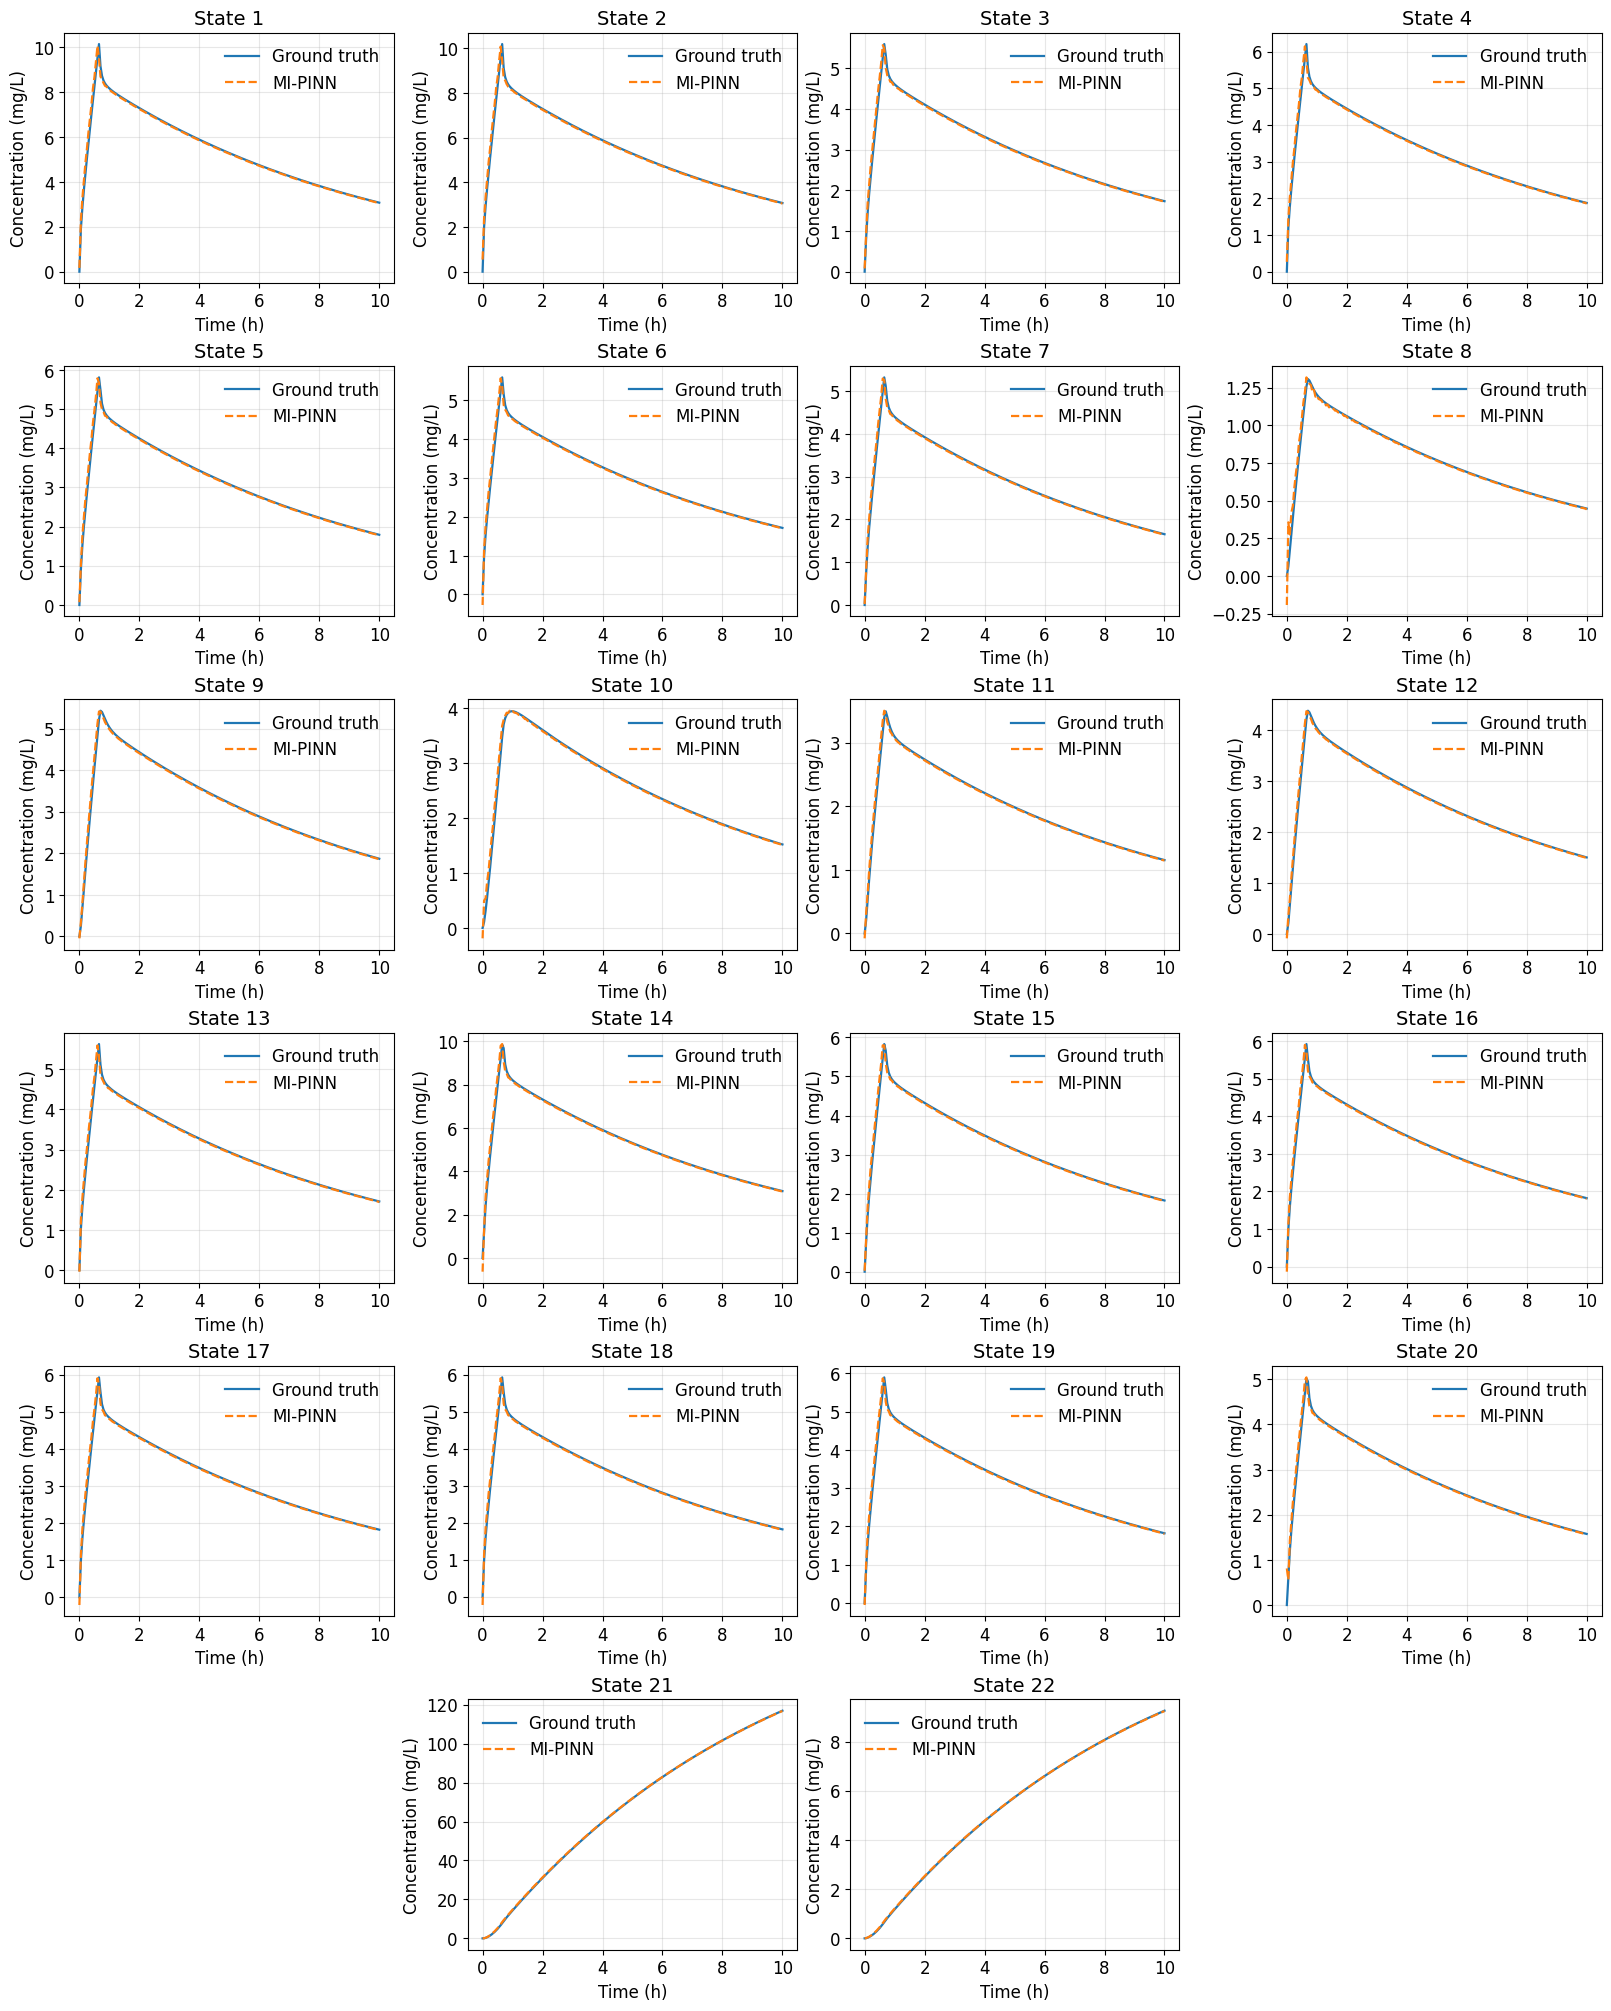

In [15]:
# jnp.save('theophylline_inverse_22', para_all[19])

params_inv = jnp.load('/home/wongj/weizhao/biology/0721/theophylline_inverse_22.npy')
# params_inv = para_all[19]
pred_all = eval_prediction(params_inv)
#pred_all_2 = eval_prediction_2(params)


mse = jnp.sum(jnp.mean(jnp.square(gt_solver - pred_all), axis=0))
print(mse)
print(jnp.mean(jnp.square(gt_solver - pred_all), axis=0))


# num_rows = 11
# num_cols = 2
# num_images = num_rows * num_cols

# fig = plt.figure(figsize=(10, 35))

# subfigs = fig.subfigures(num_rows, 1)

# for row in range(num_rows):
#     axs = subfigs[row].subplots(1, num_cols)
#     for col in range(num_cols):
#         idx = row * num_cols + col
#         axs[col].plot(t_in, gt_solver[:, idx], label=f'Ground truth {idx}')
#         axs[col].plot(t_in, pred_all[:, idx], label=f'PINN {idx}')
#         axs[col].legend()
# plt.show()


# =========================
# Inputs you already have:
#   t_in      : (T,)
#   gt_solver : (T, 22)
#   pred_all  : (T, 22)   # MI-PINN prediction
# =========================

t_in = np.asarray(t_in).reshape(-1)

gt_solver = np.asarray(gt_solver)
pred_all  = np.asarray(pred_all)

# 如果数据是 (22, T)，自动转成 (T, 22)
if gt_solver.shape[0] == 22 and gt_solver.shape[1] == len(t_in):
    gt_solver = gt_solver.T
if pred_all.shape[0] == 22 and pred_all.shape[1] == len(t_in):
    pred_all = pred_all.T

assert gt_solver.shape[0] == len(t_in)
assert pred_all.shape[0] == len(t_in)
assert gt_solver.shape[1] == pred_all.shape[1]

num_states = gt_solver.shape[1]  # 22

# ---- 4 columns layout ----
num_rows, num_cols = 6, 4  # 24 slots
fig, axes = plt.subplots(
    num_rows, num_cols,
    figsize=(16, 20),
    constrained_layout=True
)

# 让最后2张图放在最后一行中间两格 (col=1,2)
plot_positions = []
for r in range(5):          # 前5行满铺 5*4=20
    for c in range(4):
        plot_positions.append((r, c))
plot_positions += [(5, 1), (5, 2)]  # 最后一行居中 2 张

# 关闭最后一行左右两格
axes[5, 0].axis("off")
axes[5, 3].axis("off")

for idx in range(num_states):
    r, c = plot_positions[idx]
    ax = axes[r, c]

    ax.plot(t_in, gt_solver[:, idx], lw=1.6, label="Ground truth")
    ax.plot(t_in, pred_all[:, idx], lw=1.6, ls="--", label="MI-PINN")

    ax.set_title(f"State {idx+1}", fontsize=14)
    ax.grid(True, alpha=0.3)

    # 每个子图都加 x/y label（含单位）
    ax.set_xlabel("Time (h)", fontsize=12)  # 如果是小时可写 Time (h)
    ax.set_ylabel("Concentration (mg/L)", fontsize=12)

    # 每个子图都放 legend（小一点避免挡住曲线）
    ax.legend(fontsize=12, loc="best", frameon=False)

    # y轴科学计数法（可选）
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 3))

    # tick字体小一点，避免拥挤
    ax.tick_params(axis="both", labelsize=12)

# fig.suptitle("Ground Truth vs MI-PINN Prediction (22 States)", fontsize=14)

plt.show()

